# Rannacher Smoothed Vs. Naive Crank-Nicolson Analysis

## Environment Setup

In [ ]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np 
import matplotlib.pyplot as plt 
from scipy import special
from src.engines.black_scholes import bs_solver
from src.utils.convergence import plot_convergence
from src.utils.greeks import gamma, delta, theta

## Naive-Crank Nicolson Implementation and Convergence Analysis

### Discretisation

### Log-log Plots
#### Spatial Convergence


The slope of our log relation is 2.09, proving 2.0865380664125714 convergence.


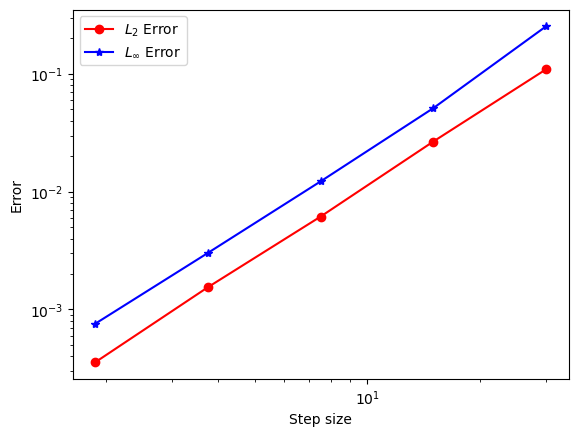

(np.float64(2.0865380664125714),
 array([30.   , 15.   ,  7.5  ,  3.75 ,  1.875]),
 array([0.25365305, 0.05124116, 0.01223164, 0.00301953, 0.00075601]))

In [ ]:
#Spatial Convergence Plot
def space_bs_wrapper(R):
    #Assigning parameters
    K = 100
    M = 100000 #Maintaining a large temporal step count to minimise error interference
    r = 0
    vol = 0.5
    T = 5.0
    f_0 = lambda t: K*np.exp(-r*t)
    d_plus = lambda t, s: 1/(vol*np.sqrt(np.maximum(t, 1e-15))) * (np.log(np.maximum(s, 1e-15)/K) + (r + ((vol**2)/2)*np.maximum(t, 1e-15)))
    d_minus = lambda t, s: 1/(vol*np.sqrt(np.maximum(t, 1e-15))) * (np.log(np.maximum(s, 1e-15)/K) + (r - ((vol**2)/2)*np.maximum(t, 1e-15)))
    phi = lambda s: 1/2 * special.erfc(-s/np.sqrt(2))
    f_R = lambda t, s: K*np.exp(-r*t)*phi(-d_minus(t, s))-s*phi(-d_plus(t, s))
    g = lambda s: np.maximum(K-s, 0)
    
    #Defining our step size
    ds = 3*K/R
    
    #Asigning our exact and numerical solution
    V_num, s, t = bs_solver(R, M, f_0, f_R, g, vol, r, T, K, CN)
    V_exact = f_R(T, s)

    #Finding Error
    L_inf_error = np.max(np.abs(V_num[:, -1] - V_exact))
    L2_error = np.sqrt((ds/(3*K))*np.sum((V_num[:, -1] - V_exact)**2))
    
    return ds, L2_error, L_inf_error

R_values = [10, 20, 40, 80, 160]

plot_convergence(space_bs_wrapper, R_values)

#### Temporal Convergence


The slope of our log relation is 0.99, proving 0.990576313275957 convergence.


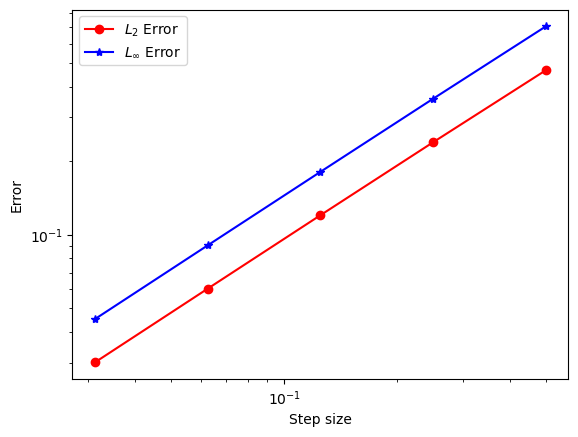

(np.float64(0.990576313275957),
 array([0.5    , 0.25   , 0.125  , 0.0625 , 0.03125]),
 array([0.70504299, 0.35767438, 0.18014298, 0.0903983 , 0.04528074]))

In [ ]:
#Temporal Convergence Plot
def time_bs_wrapper(M):
    #Assigning parameters
    K = 100
    r = 0
    vol = 0.5
    T = 5.0
    R = 10000
    f_0 = lambda t: K*np.exp(-r*t)
    d_plus = lambda t, s: 1/(vol*np.sqrt(np.maximum(t, 1e-15))) * (np.log(np.maximum(s, 1e-15)/K) + (r + ((vol**2)/2)*np.maximum(t, 1e-15)))
    d_minus = lambda t, s: 1/(vol*np.sqrt(np.maximum(t, 1e-15))) * (np.log(np.maximum(s, 1e-15)/K) + (r - ((vol**2)/2)*np.maximum(t, 1e-15)))
    phi = lambda s: 1/2 * special.erfc(-s/np.sqrt(2))
    f_R = lambda t, s: K*np.exp(-r*t)*phi(-d_minus(t, s))-s*phi(-d_plus(t, s))
    g = lambda s: np.maximum(K-s, 0)

    #Defining our step size
    dt = T/M
    ds = 3*K/R

    #Asigning our exact and numerical solution
    V_num, s, t = bs_solver(R, M, f_0, f_R, g, vol, r, T, K, CN)
    V_exact = f_R(T, s)

    #Finding Error
    L_inf_error = np.max(np.abs(V_num[:, -1] - V_exact))
    L2_error = np.sqrt((ds/(3*K))*np.sum((V_num[:, -1] - V_exact)**2))
    
    return dt, L2_error, L_inf_error

M_values = [10, 20, 40, 80, 160]

plot_convergence(time_bs_wrapper, M_values)

### Greeks (Naive)


## Rannacher Smoothed Crank-Nicolson Implementation and Convergence Analysis

### Discretisation

### Log-log Plots
#### Spatial Convergence


The slope of our log relation is 2.09, proving 2.0865380664125714 convergence.


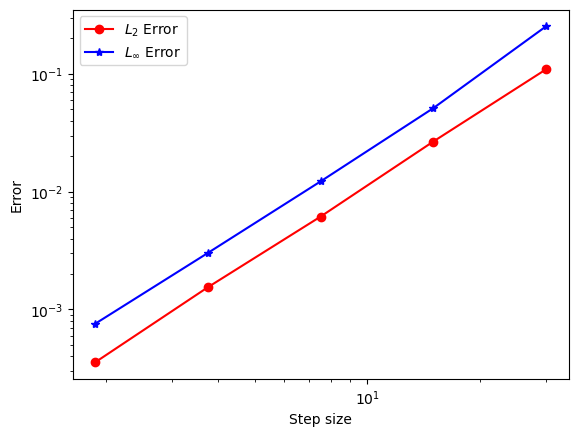

(np.float64(2.0865380664125714),
 array([30.   , 15.   ,  7.5  ,  3.75 ,  1.875]),
 array([0.25365305, 0.05124116, 0.01223164, 0.00301953, 0.00075601]))

In [ ]:
#Spatial Convergence Plot
def space_bs_wrapper(R):
    #Assigning parameters
    K = 100
    M = 100000 #Maintaining a large temporal step count to minimise error interference
    r = 0
    vol = 0.5
    T = 5.0
    f_0 = lambda t: K*np.exp(-r*t)
    d_plus = lambda t, s: 1/(vol*np.sqrt(np.maximum(t, 1e-15))) * (np.log(np.maximum(s, 1e-15)/K) + (r + ((vol**2)/2)*np.maximum(t, 1e-15)))
    d_minus = lambda t, s: 1/(vol*np.sqrt(np.maximum(t, 1e-15))) * (np.log(np.maximum(s, 1e-15)/K) + (r - ((vol**2)/2)*np.maximum(t, 1e-15)))
    phi = lambda s: 1/2 * special.erfc(-s/np.sqrt(2))
    f_R = lambda t, s: K*np.exp(-r*t)*phi(-d_minus(t, s))-s*phi(-d_plus(t, s))
    g = lambda s: np.maximum(K-s, 0)
    
    #Defining our step size
    ds = 3*K/R
    
    #Asigning our exact and numerical solution
    V_num, s, t = bs_solver(R, M, f_0, f_R, g, vol, r, T, K, RS)
    V_exact = f_R(T, s)

    #Finding Error
    L_inf_error = np.max(np.abs(V_num[:, -1] - V_exact))
    L2_error = np.sqrt((ds/(3*K))*np.sum((V_num[:, -1] - V_exact)**2))
    
    return ds, L2_error, L_inf_error

R_values = [10, 20, 40, 80, 160]

plot_convergence(space_bs_wrapper, R_values)

#### Temporal Convergence


The slope of our log relation is 0.99, proving 0.990576313275957 convergence.


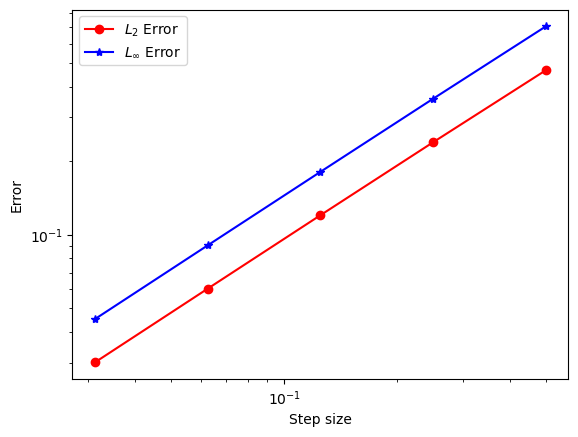

(np.float64(0.990576313275957),
 array([0.5    , 0.25   , 0.125  , 0.0625 , 0.03125]),
 array([0.70504299, 0.35767438, 0.18014298, 0.0903983 , 0.04528074]))

In [ ]:
#Temporal Convergence Plot
def time_bs_wrapper(M):
    #Assigning parameters
    K = 100
    r = 0
    vol = 0.5
    T = 5.0
    R = 10000
    f_0 = lambda t: K*np.exp(-r*t)
    d_plus = lambda t, s: 1/(vol*np.sqrt(np.maximum(t, 1e-15))) * (np.log(np.maximum(s, 1e-15)/K) + (r + ((vol**2)/2)*np.maximum(t, 1e-15)))
    d_minus = lambda t, s: 1/(vol*np.sqrt(np.maximum(t, 1e-15))) * (np.log(np.maximum(s, 1e-15)/K) + (r - ((vol**2)/2)*np.maximum(t, 1e-15)))
    phi = lambda s: 1/2 * special.erfc(-s/np.sqrt(2))
    f_R = lambda t, s: K*np.exp(-r*t)*phi(-d_minus(t, s))-s*phi(-d_plus(t, s))
    g = lambda s: np.maximum(K-s, 0)

    #Defining our step size
    dt = T/M
    ds = 3*K/R

    #Asigning our exact and numerical solution
    V_num, s, t = bs_solver(R, M, f_0, f_R, g, vol, r, T, K, RS)
    V_exact = f_R(T, s)

    #Finding Error
    L_inf_error = np.max(np.abs(V_num[:, -1] - V_exact))
    L2_error = np.sqrt((ds/(3*K))*np.sum((V_num[:, -1] - V_exact)**2))
    
    return dt, L2_error, L_inf_error

M_values = [10, 20, 40, 80, 160]

plot_convergence(time_bs_wrapper, M_values)

### Greeks (Rannacher Smoothed)


## Discussion
### Convergence

### Rannacher Smoothed Vs. Naive C-N

### Comparison to BTCS

### Condition Number and Ill Conditioning


## Summary
